# Sprint 2: End-to-End Pipeline

This notebook loads the prepared GitSkills DuckDB database and runs `summarize_cohort()` directly on a pinned list of candidate families. The summarizer reuses compatible scan files in `results/.scans/` and regenerates stale or missing scans; it does not require saved `analyze_family` reports or SkillTrace output. Full similarity evidence is held in memory only while selecting manual-review examples.

### Project Imports

In [31]:
import json
import os
from pathlib import Path

import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import SVG, display

from gitskills.analysis.family_models import SimilarityPolicy
from gitskills.pipelines.cohort import summarize_cohort

### Set Variables

In [32]:
DEFAULT_DB_PATH = Path(r"C:\data\duckdb\agent_skills_release.db")
DB_PATH = Path(
    os.environ.get("GITSKILLS_DB", DEFAULT_DB_PATH)
)
if not DB_PATH.is_file():
    raise FileNotFoundError(f"Prepared DuckDB not found: {DB_PATH}. Set GITSKILLS_DB.")

PROJECT_ROOT = next(
    (directory for directory in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (directory / "pyproject.toml").is_file() and (directory / "notebooks").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Start Jupyter from the project repository (or a directory beneath it).")

NOTEBOOK_DIR = PROJECT_ROOT / "notebooks" / "end_to_end_pipeline"
RUN_LABEL = "sprint2"
RESULT_DIR = NOTEBOOK_DIR / "results" / RUN_LABEL

### Locate Database

In [33]:
print(f"Database: {DB_PATH}")
print(f"Size: {DB_PATH.stat().st_size / 1024**3:.2f} GB")

Database: C:\data\duckdb\agent_skills_release.db
Size: 37.37 GB


### Connect to DuckDB

In [34]:
with duckdb.connect(database=str(DB_PATH), read_only=True) as connection:
    duckdb_version = connection.execute("SELECT version()").fetchone()[0]
    available_tables = {row[0] for row in connection.execute("SHOW TABLES").fetchall()}
    required_tables = {"artifacts", "artifact_groupings", "artifact_siblings", "repos"}
    if missing := required_tables - available_tables:
        raise RuntimeError(f"Prepare the analysis database first; missing tables: {sorted(missing)}")

print(f"DuckDB {duckdb_version} | {DB_PATH}")
print(f"Results: {RESULT_DIR.relative_to(PROJECT_ROOT)}")
print(f"Scan cache: {(RESULT_DIR / '.scans').relative_to(PROJECT_ROOT)}")

DuckDB v2.0.0 | C:\data\duckdb\agent_skills_release.db
Results: notebooks\end_to_end_pipeline\results\sprint2
Scan cache: notebooks\end_to_end_pipeline\results\sprint2\.scans


### Select candidate families

Edit the list as the study evolves. Each name is matched exactly against `artifact_groupings.name`. The existing SkillTrace reports are a starting cohort, **not an automatically approved research sample**. Set `APPROVAL_REFERENCE` to the team decision/date after approval; the manifest otherwise marks the cohort provisional. All directed edges (primary and additional) are included; ambiguous relationships remain eligible only for relationship validation.

In [35]:
candidate_families = [
    "003-create-golang-project",
    "1k-defi-module-integration",
    "A/B Test Setup",
    "argent-react-native-app-workflow",
    "busybox-on-windows",
    "capacitor-best-practices",
    "cometchat-core",
    "cursor-subagent-creator",
    "databricks-upgrade-migration",
    "ghostclaw",
    "hello-world",
    "legacy-migration-planner",
    "python-patterns"
]

POLICY = SimilarityPolicy()  # Shared similarity/direction thresholds; see RDR-004 and RDR-007.
EDGES = "all"  # Both primary and additional direction-supported comparisons.
PER_STRATUM = 5
SEED = 580
APPROVAL_REFERENCE = None  # Set to a recorded team decision/date after approval.

if len(candidate_families) != len(set(candidate_families)) or not candidate_families:
    raise ValueError("Use a nonempty list of unique family names")
print(f"Selected families: {len(candidate_families)}")

Selected families: 13


### Summarize the selected cohort

The summarizer loads each selected family from DuckDB, runs the family analyzer for relationship validation, and reuses compatible `results/.scans/<family>.json` reports when available. It creates or refreshes missing/stale scans and produces research tables, figures, audit records, and manual-review templates. Only compact scan reports are saved; no verbose analysis JSON or SkillTrace reports are needed. Use `rescan=True` to force all scans to be rebuilt.

In [36]:
execution = summarize_cohort(
    candidate_families,
    database=DB_PATH,
    results=RESULT_DIR,
    policy=POLICY,
    edges=EDGES,
    per_stratum=PER_STRATUM,
    seed=SEED,
    approval_reference=APPROVAL_REFERENCE,
)

display(pd.DataFrame([execution]))
print(f"Research summary: {RESULT_DIR / 'review' / 'summary.json'}")
print(f"Sample manifest: {RESULT_DIR / 'sample_manifest.json'}")
print(f"Processing audit: {RESULT_DIR / 'audit' / 'processing_summary.csv'}")

,status,input_coverage,family_count,artifacts_loaded,artifacts_skipped,directed_pairs_analyzed,pairs_incomplete,validation_status,result_directory
0,complete,complete,13,487,0,3425,3,awaiting independent review/adjudication,\\boxy\home\school\umich\csc580\git\csc580-pro...


Research summary: \\boxy\home\school\umich\csc580\git\csc580-project8\notebooks\end_to_end_pipeline\results\sprint2\review\summary.json
Sample manifest: \\boxy\home\school\umich\csc580\git\csc580-project8\notebooks\end_to_end_pipeline\results\sprint2\sample_manifest.json
Processing audit: \\boxy\home\school\umich\csc580\git\csc580-project8\notebooks\end_to_end_pipeline\results\sprint2\audit\processing_summary.csv


### Check research outputs

The generated scan cache resides under `.scans/`, independently of SkillTrace's compact lineage reports. The following section confirms which families were processed and the number of directed comparisons in each report.

In [37]:
runs = pd.read_csv(RESULT_DIR / "audit" / "processing_summary.csv")
display(runs[["family", "artifacts_loaded", "artifacts_skipped", "pairs_analyzed", "pairs_incomplete"]])

,family,artifacts_loaded,artifacts_skipped,pairs_analyzed,pairs_incomplete
0,003-create-golang-project,4,0,1,0
1,1k-defi-module-integration,4,0,3,0
2,A/B Test Setup,2,0,0,0
3,argent-react-native-app-workflow,5,0,4,0
4,busybox-on-windows,26,0,174,0
5,capacitor-best-practices,3,0,3,2
6,cometchat-core,5,0,7,0
7,cursor-subagent-creator,5,0,9,0
8,databricks-upgrade-migration,5,0,0,0
9,ghostclaw,5,0,4,0


### Preliminary results: directed comparisons

Counts describe **direction-supported comparisons**, not independent security incidents or distinct artifacts. A *flagged* pair is a broader category than a pair with a scanner-supported risk indicator; manual validation is still pending.

,Pairs,Percent
Not flagged,2596,75.8
Flagged without supported indicator,662,19.3
With supported indicator,167,4.9


220 individual indicator findings across 167 pairs


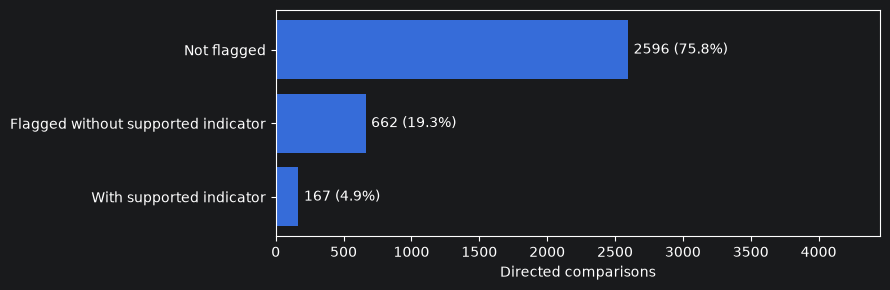

In [38]:
REVIEW_DIR = RESULT_DIR / "review"
FIGURES_DIR = RESULT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

with (REVIEW_DIR / "summary.json").open(encoding="utf-8") as file:
    summary = json.load(file)

total = summary["directed_pairs_analyzed"]
flagged = summary["flagged_pairs"]
indicated = summary["pairs_with_supported_indicators"]
if not 0 <= indicated <= flagged <= total:
    raise ValueError("Inconsistent directed-pair counts in summary.json")

outcomes = pd.Series({
    "Not flagged": total - flagged,
    "Flagged without supported indicator": flagged - indicated,
    "With supported indicator": indicated,
})
display(pd.DataFrame({
    "Pairs": outcomes,
    "Percent": (100 * outcomes / total).round(1) if total else 0.0,
}))
print(f"{summary['supported_findings']} individual indicator findings across {indicated} pairs")

if total:
    fig, ax = plt.subplots(figsize=(9, 3))
    bars = ax.barh(outcomes.index, outcomes.values)
    ax.bar_label(bars, labels=[f"{count} ({count / total:.1%})" for count in outcomes], padding=4)
    ax.set_xlim(0, total * 1.3)
    ax.set_xlabel("Directed comparisons")
    ax.invert_yaxis()
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "pair_outcomes.svg", bbox_inches="tight")
    plt.show()
else:
    print("No direction-supported comparisons in this cohort.")

### Results by candidate family

Compare the number of analyzed pairs with the number containing indicators. Rates use each family's **own** pair count; families without directed comparisons have no rate. The selected cohort is not a random sample of GitSkills.

,family,artifacts_loaded,pairs_analyzed,pairs_flagged,pairs_with_indicators,indicator_rate_pct
12,python-patterns,247,3207,764,159,5.0
4,busybox-on-windows,26,174,34,0,0.0
7,cursor-subagent-creator,5,9,7,0,0.0
11,legacy-migration-planner,5,9,7,0,0.0
6,cometchat-core,5,7,7,3,42.9
10,hello-world,171,4,0,0,0.0
9,ghostclaw,5,4,1,1,25.0
3,argent-react-native-app-workflow,5,4,4,0,0.0
1,1k-defi-module-integration,4,3,2,1,33.3
5,capacitor-best-practices,3,3,2,2,66.7


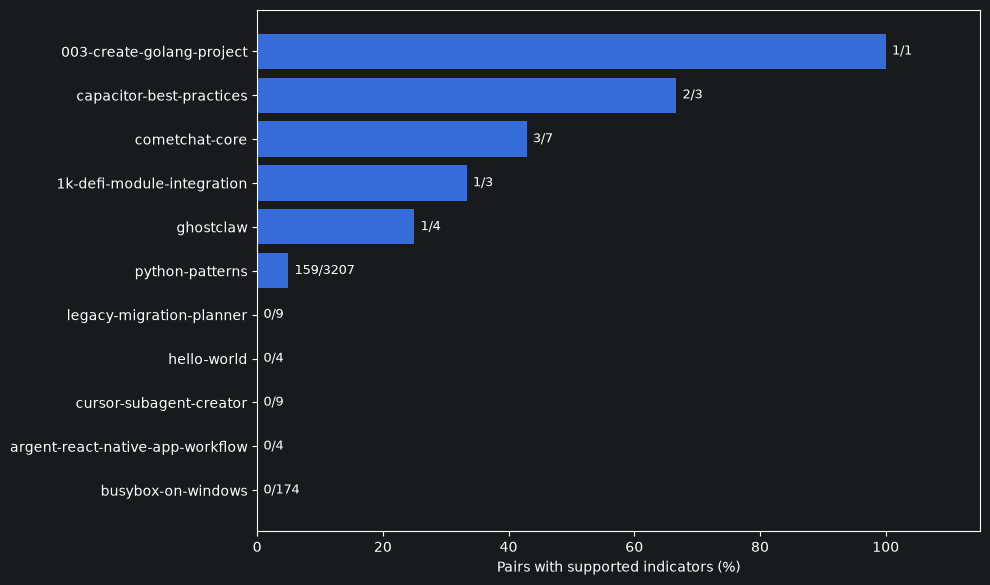

No direction-supported comparisons: A/B Test Setup, databricks-upgrade-migration
Cohort imbalance: python-patterns contributes 93.6% of directed comparisons.


In [39]:
families = pd.read_csv(REVIEW_DIR / "families.csv")
if set(families["family"]) != set(candidate_families):
    raise ValueError("families.csv does not match the selected candidate_families")

families["indicator_rate_pct"] = (
    100 * families["pairs_with_indicators"]
    / families["pairs_analyzed"].replace(0, float("nan"))
)
display(families[[
    "family", "artifacts_loaded", "pairs_analyzed", "pairs_flagged",
    "pairs_with_indicators", "indicator_rate_pct",
]].sort_values("pairs_analyzed", ascending=False).round({"indicator_rate_pct": 1}))

comparable = families.loc[families["pairs_analyzed"] > 0].sort_values("indicator_rate_pct")
if not comparable.empty:
    fig, ax = plt.subplots(figsize=(10, max(3, len(comparable) * 0.45 + 1)))
    bars = ax.barh(comparable["family"], comparable["indicator_rate_pct"])
    for bar, (_, row) in zip(bars, comparable.iterrows()):
        ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
                f"{int(row['pairs_with_indicators'])}/{int(row['pairs_analyzed'])}",
                va="center", fontsize=9)
    ax.set_xlim(0, 115)
    ax.set_xlabel("Pairs with supported indicators (%)")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "indicators_by_family.svg", bbox_inches="tight")
    plt.show()

no_pairs = families.loc[families["pairs_analyzed"] == 0, "family"].tolist()
if no_pairs:
    print(f"No direction-supported comparisons: {', '.join(no_pairs)}")
if total:
    largest = families.sort_values("pairs_analyzed", ascending=False).iloc[0]
    if largest["pairs_analyzed"] > total / 2:
        print(f"Cohort imbalance: {largest['family']} contributes "
              f"{largest['pairs_analyzed'] / total:.1%} of directed comparisons.")

### Risk indicators detected

Display the figure already generated by `summarize_cohort()` and the observed indicator types. Counts are **pairs containing an indicator**, not finding occurrences; one pair may contain multiple indicator types.

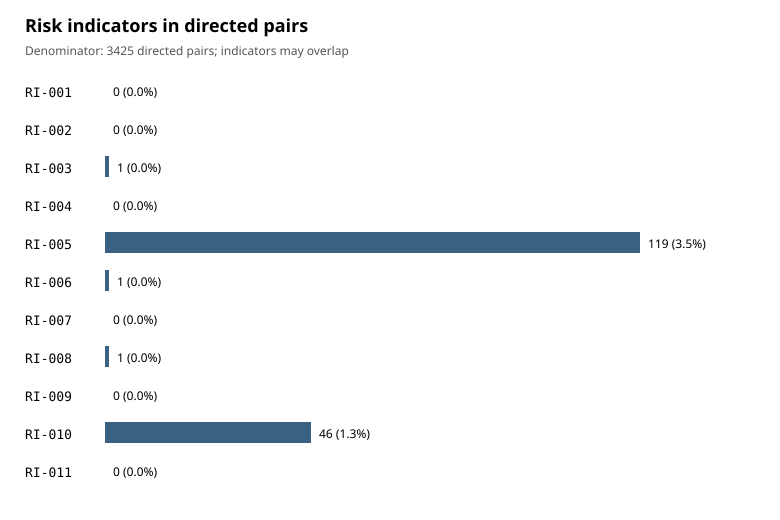

,Indicator,Description,Pairs,Percent of directed pairs
4,RI-005,External package or script acquisition,119,3.5
9,RI-010,Local script invocation or content change,46,1.3
2,RI-003,New network destination or outbound transfer,1,0.0
5,RI-006,Destructive or privileged file operation,1,0.0
7,RI-008,System or permissions modification,1,0.0


In [40]:
display(SVG(filename=str(FIGURES_DIR / "indicator_frequency.svg")))

indicator_labels = {
    "RI-001": "Download-to-interpreter execution",
    "RI-002": "Remote execution source changed",
    "RI-003": "New network destination or outbound transfer",
    "RI-004": "Weakened network verification/transport",
    "RI-005": "External package or script acquisition",
    "RI-006": "Destructive or privileged file operation",
    "RI-007": "Credential access or outbound reference",
    "RI-008": "System or permissions modification",
    "RI-009": "Sensitive file operation",
    "RI-010": "Local script invocation or content change",
    "RI-011": "External instruction dependency change",
}
frequency = pd.read_csv(REVIEW_DIR / "indicator_frequency.csv")
observed = frequency.loc[frequency["pairs"] > 0].copy()
observed["Description"] = observed["indicator_id"].map(indicator_labels).fillna("See scanner report")
display(observed[["indicator_id", "Description", "pairs", "percent_of_directed_pairs"]]
        .sort_values("pairs", ascending=False).rename(columns={
            "indicator_id": "Indicator", "pairs": "Pairs",
            "percent_of_directed_pairs": "Percent of directed pairs",
        }).round(1))
if observed.empty:
    print("No supported risk indicators in the selected cohort.")

### Edge types and analysis coverage

Primary and additional edges can share source artifacts; their rates are descriptive, not independent risk estimates. Ambiguous relationships are excluded from directed scanning but remain eligible for relationship validation.

,edge_type,pairs_analyzed,pairs_flagged,pairs_with_indicators,indicator_rate_pct,pairs_coverage_incomplete
0,primary,168,53,8,4.8,2
1,additional,3257,776,159,4.9,1


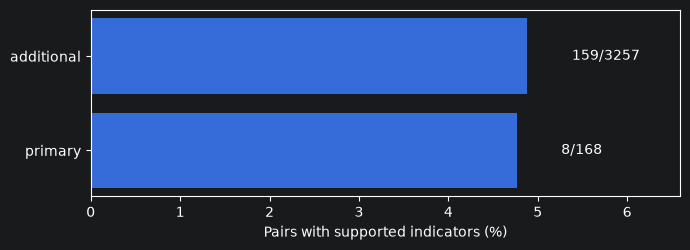

,Count
Artifacts loaded,487
Artifacts skipped,0
Pairs with changed evidence,826
Pairs with changed sibling evidence,151
Pairs with incomplete evidence coverage,3
Ambiguous edges not direction-scanned,1013
Directed review samples,28
Relationship review samples,15


Validation: awaiting independent review/adjudication


In [41]:
edges = pd.read_csv(REVIEW_DIR / "edge_types.csv")
edges["indicator_rate_pct"] = (
    100 * edges["pairs_with_indicators"]
    / edges["pairs_analyzed"].replace(0, float("nan"))
)
display(edges[[
    "edge_type", "pairs_analyzed", "pairs_flagged", "pairs_with_indicators",
    "indicator_rate_pct", "pairs_coverage_incomplete",
]].round({"indicator_rate_pct": 1}))

edge_plot = edges.loc[edges["pairs_analyzed"] > 0]
if not edge_plot.empty:
    fig, ax = plt.subplots(figsize=(7, 2.6))
    bars = ax.barh(edge_plot["edge_type"], edge_plot["indicator_rate_pct"])
    for bar, (_, row) in zip(bars, edge_plot.iterrows()):
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
                f"{int(row['pairs_with_indicators'])}/{int(row['pairs_analyzed'])}",
                va="center")
    ax.set_xlim(0, max(5, edge_plot["indicator_rate_pct"].max() * 1.35))
    ax.set_xlabel("Pairs with supported indicators (%)")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "indicators_by_edge_type.svg", bbox_inches="tight")
    plt.show()

with (RESULT_DIR / "execution_summary.json").open(encoding="utf-8") as file:
    execution_summary = json.load(file)
coverage = pd.Series({
    "Artifacts loaded": execution_summary["artifacts_loaded"],
    "Artifacts skipped": execution_summary["artifacts_skipped"],
    "Pairs with changed evidence": summary["pairs_with_evidence_changes"],
    "Pairs with changed sibling evidence": summary["pairs_with_sibling_evidence_changes"],
    "Pairs with incomplete evidence coverage": summary["pairs_with_incomplete_evidence_coverage"],
    "Ambiguous edges not direction-scanned": summary["ambiguous_edges_skipped"],
    "Directed review samples": summary["sampling"]["sampled_pairs"],
    "Relationship review samples": summary["relationship_sampling"]["sampled_pairs"],
})
display(coverage.rename("Count").to_frame())
print(f"Validation: {execution_summary['validation_status']}")

### Findings for manual review

Each row is a directed artifact comparison containing at least one scanner-supported indicator. Use its source IDs to locate the original artifacts in `sample_manifest.json` or SkillTrace. Incomplete coverage requires particular care; these are **review candidates**, not confirmed vulnerabilities.

In [42]:
directed = pd.read_csv(REVIEW_DIR / "directed_pairs.csv")
if len(directed) != total:
    raise ValueError("directed_pairs.csv does not match summary.json")

findings = directed.loc[directed["indicator_ids"].fillna("").str.strip().ne("")].copy()
display(findings[[
    "family", "base_artifact_id", "derived_artifact_id", "edge_type",
    "direction_basis", "indicator_ids", "finding_count", "coverage_status",
]].sort_values(["family", "base_artifact_id", "derived_artifact_id"]).reset_index(drop=True))
print(f"{len(findings)} pairs to inspect; "
      f"{(findings['coverage_status'] != 'complete').sum()} with incomplete coverage.")

,family,base_artifact_id,derived_artifact_id,edge_type,direction_basis,indicator_ids,finding_count,coverage_status
0,003-create-golang-project,1970318,2244377,primary,containment,RI-006,1,complete
1,1k-defi-module-integration,2696303,3076631,primary,chronology,RI-003;RI-008,2,complete
2,capacitor-best-practices,2627824,2630854,primary,chronology,RI-005,4,incomplete
3,capacitor-best-practices,2627824,2630982,additional,chronology,RI-005,4,incomplete
4,cometchat-core,3485370,3572584,additional,containment,RI-005,1,complete
...,...,...,...,...,...,...,...,...
162,python-patterns,3309945,3427701,additional,containment,RI-005,1,complete
163,python-patterns,3323472,3427701,additional,containment,RI-005,1,complete
164,python-patterns,3324410,3427701,additional,containment,RI-005,1,complete
165,python-patterns,3752295,2688856,additional,containment,RI-010,2,complete


167 pairs to inspect; 2 with incomplete coverage.


### Independent review and adjudication (team action)

The pipeline is complete when the outputs above are written; **human validation is separate**. Follow [`docs/validation/manual_validation_protocol.md`](../../docs/validation/manual_validation_protocol.md):

1. Give each reviewer an independent copy of `manual-review/directed-pairs/validation_annotations_template.csv` and `manual-review/relationship-pairs/relationship_validation_annotations_template.csv`.
2. Inspect source artifacts and siblings using the IDs and paths in `sample_manifest.json` and SkillTrace. Do not run stored scripts.
3. Preserve individual reviews and resolve disagreements in separate adjudicated CSVs (recommended: `manual-review/adjudicated/`). Do not overwrite generated templates.
4. Once both reviews are adjudicated, run the optional cell below. It verifies the saved cohort and validation samples, then updates `review/summary.json` without rerunning family similarity analysis or security scans.

If the cohort, policy, or rules change after review begins, archive the old results and validation copies before creating a new sample.

In [43]:
directed_review = RESULT_DIR / "manual-review" / "adjudicated" / "directed.csv"
relationship_review = RESULT_DIR / "manual-review" / "adjudicated" / "relationships.csv"

if directed_review.is_file() and relationship_review.is_file():
    completed = summarize_cohort(
        candidate_families, database=DB_PATH, results=RESULT_DIR, policy=POLICY, edges=EDGES, per_stratum=PER_STRATUM, seed=SEED,
        approval_reference=APPROVAL_REFERENCE,
        directed_annotations=directed_review,
        relationship_annotations=relationship_review,
    )
    print("Adjudicated sample metrics written to review/summary.json")
else:
    print("Manual review is pending. See manual-review/ and copy the templates for reviewers.")

Manual review is pending. See manual-review/ and copy the templates for reviewers.
